# Relative strength rotation, 2-hour rebalance (hourly bars)

This backtests the **intraday variant** of the relative strength rotation strategy that now
runs live on Webull (`live/relative_strength_rotation_webull_intraday.py`): same mechanic as
the original monthly strategy — rank the halal universe by trailing return, hold the top 10
equal-weighted — but with a 6-hourly-bar lookback (roughly one trading day) instead of 3
months, re-evaluated every 2 hourly bars instead of once a month. Tickers come from
`equities-list.csv` (rows with `Asset Type == Stock`; ETFs excluded, same as the original).
The CSV labels these as halal *candidates* only — independently verify current Shariah
compliance before investing.

**This notebook did not exist before the live script went live.** The live script's `DRY_RUN`
default is standing in for the validation a backtest would normally provide ahead of time.
This notebook is that validation, after the fact — read the caveats at the bottom before
treating anything here as a reason to trust the live version with more capital.

**Strategy specification**

- Universe: the halal candidate stocks in `equities-list.csv`, same screen as every other
  notebook in this project.
- Signal: trailing return over the last `LOOKBACK_BARS` hourly bars (no skip bar) — the direct
  intraday analog of the original's trailing-3-month, no-skip-month score.
- Rebalance: every `REBALANCE_BARS` hourly bars. `LOOKBACK_BARS = 6` and `REBALANCE_BARS = 2`
  keep the original's 3:1 lookback-to-rebalance ratio (3 months of lookback for a 1-month
  rebalance), just scaled down to hours.
- Selection: top 10 by score, equal-weighted, full rebalance every cycle — no hold-band,
  matching the original (and the live script).
- Fallback: if fewer than `MIN_UNIVERSE` names are scoreable at a decision point (e.g. early
  in the data, or a lot of missing bars), hold the previous basket unchanged rather than
  trading into a thin ranking — same fallback the original notebook and the live script use.

Like every monthly notebook in this project, this uses **return-averaging** rather than an
explicit share/cash ledger: for a strategy that fully rebalances every cycle (no hold-band),
the equal-weighted average of the selected names\' returns over a holding window is
mathematically identical to actually liquidating and rebuying — proven and used throughout
this project\'s other notebooks.


In [1]:
from pathlib import Path
import csv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EQUITIES_LIST_PATH = Path('equities-list.csv')
DATA_DIR = Path('data') / 'hourly'

with open(EQUITIES_LIST_PATH, newline='') as f:
    equities_rows = list(csv.DictReader(f))
UNIVERSE = [row['Ticker'] for row in equities_rows if row['Asset Type'] == 'Stock']
print(f'{len(UNIVERSE)} candidate halal stocks in the universe')

START_DATE = pd.Timestamp('2009-01-01', tz='UTC')

# Strategy parameters
LOOKBACK_BARS = 6       # trailing-return lookback, in hourly bars (~1 trading day)
REBALANCE_BARS = 2      # rebalance cadence, in hourly bars (~2 trading hours) — matches the live script
TOP_N = 10              # concentrated top-10 roster, same as the original monthly strategy
MIN_UNIVERSE = 15       # minimum scoreable names required before trading a given cycle

# Hourly bar geometry: US regular hours = 09:30 half-hour bar + six 1-hour bars = 7 bars/session.
BARS_PER_SESSION = 7
TRADING_DAYS_PER_YEAR = 252
PERIODS_PER_YEAR = (BARS_PER_SESSION * TRADING_DAYS_PER_YEAR) / REBALANCE_BARS  # for annualizing bar-level stats

INVESTMENT_2026_DOLLARS = 150.0
TARGET_CPI = None  # leave None to use the latest available CPI reading from FRED


132 candidate halal stocks in the universe


## Load the cached hourly bars

Reuses the same `data/hourly/{TICKER}.csv` cache the live script and the hourly-converted
monthly notebooks share — built once from IBKR, read-only here. No download cell: this
notebook assumes the cache is already populated (every ticker in the universe was fetched
earlier in this project).

In [2]:
def load_cached_hourly(ticker):
    frame = pd.read_csv(DATA_DIR / f'{ticker}.csv', parse_dates=['date'], index_col='date')
    frame.index = pd.DatetimeIndex(frame.index).tz_convert('UTC')
    return frame.sort_index()

hourly_closes = {}
missing = []
for ticker in UNIVERSE:
    cache_path = DATA_DIR / f'{ticker}.csv'
    if not cache_path.exists():
        missing.append(ticker)
        continue
    bars = load_cached_hourly(ticker)
    if bars.empty:
        missing.append(ticker)
        continue
    hourly_closes[ticker] = bars['close']

if missing:
    print(f'{len(missing)} tickers missing from the hourly cache, excluded: {missing}')

price_panel = pd.DataFrame(hourly_closes).sort_index()
price_panel = price_panel.loc[price_panel.index >= START_DATE]
# Fill isolated missing bars (at most one session) so bar-count rolling windows stay contiguous,
# same convention as the hourly-converted monthly notebooks.
price_panel = price_panel.ffill(limit=BARS_PER_SESSION)

print(f'{price_panel.shape[1]} tickers, {price_panel.shape[0]:,} hourly bars '
      f'from {price_panel.index.min()} to {price_panel.index.max()}')


132 tickers, 32,366 hourly bars from 2009-01-02 14:30:00+00:00 to 2026-09-30 16:00:00+00:00


## Decision loop

Every `REBALANCE_BARS` bars, score the universe using the trailing `LOOKBACK_BARS`-bar return,
pick the top 10, and record the equal-weighted average return of that basket over the next
`REBALANCE_BARS` bars (return-averaging, as above). `MIN_i` guarantees the very first decision
has a full `LOOKBACK_BARS`-bar lookback and a full `REBALANCE_BARS`-bar holding window ahead
of it.

In [3]:
dates = price_panel.index
n = len(dates)
MIN_i = LOOKBACK_BARS + REBALANCE_BARS

portfolio_returns = pd.Series(index=dates, dtype=float)
holdings_log = {}
turnover_log = {}
previous_holdings = set()

for j in range(MIN_i, n - REBALANCE_BARS, REBALANCE_BARS):
    score = (price_panel.iloc[j] / price_panel.iloc[j - LOOKBACK_BARS] - 1).dropna()
    hold_start_date = dates[j]
    hold_end_date = dates[j + REBALANCE_BARS]

    if len(score) < MIN_UNIVERSE:
        selected = sorted(previous_holdings)
    else:
        ranked = score.sort_values(ascending=False)
        selected = ranked.head(TOP_N).index.tolist()

    holdings_log[hold_end_date] = selected
    if selected:
        realized = (price_panel.loc[hold_end_date, selected] / price_panel.loc[hold_start_date, selected] - 1).dropna()
        portfolio_returns.loc[hold_end_date] = realized.mean() if len(realized) else np.nan
        turnover_log[hold_end_date] = len(set(selected) - previous_holdings) / TOP_N
    else:
        portfolio_returns.loc[hold_end_date] = np.nan
        turnover_log[hold_end_date] = 0.0
    previous_holdings = set(selected)

portfolio_returns = portfolio_returns.dropna()
turnover = pd.Series(turnover_log).reindex(portfolio_returns.index)
print(f'{len(portfolio_returns):,} tradable 2-hour cycles, average turnover '
      f'{turnover.mean():.0%} of the 10-name roster per cycle')


16,178 tradable 2-hour cycles, average turnover 51% of the 10-name roster per cycle


### Latest cycle: example ranking

The most recently formed basket, in the same shape as the monthly notebook\'s ranking table.

In [4]:
last_hold_date = max(holdings_log)
last_j = list(dates).index(last_hold_date) - REBALANCE_BARS
last_score = (price_panel.iloc[last_j] / price_panel.iloc[last_j - LOOKBACK_BARS] - 1).dropna()

example_table = last_score.sort_values(ascending=False).to_frame('trailing_6bar_return')
example_table['rank'] = range(1, len(example_table) + 1)
example_table['held'] = example_table.index.isin(holdings_log[last_hold_date])
example_table['trailing_6bar_return'] = (example_table['trailing_6bar_return'] * 100).round(2)
print(f'Ranking used to form the basket held through {last_hold_date}:')
display(example_table.head(15))


Ranking used to form the basket held through 2026-09-30 15:00:00+00:00:


,trailing_6bar_return,rank,held
URI,2.27,1,True
SNY,1.46,2,True
UL,1.11,3,True
GOLD,1.06,4,True
WM,0.68,5,True
NVS,0.66,6,True
RIO,0.59,7,True
SHW,0.56,8,True
PH,0.54,9,True
VALE,0.53,10,True


## General statistics

Same shape of summary as the other notebooks, but annualized using `PERIODS_PER_YEAR` (derived
from 7 bars/session and `REBALANCE_BARS`) instead of 12 — this is the correct annualization
for a series observed once per rebalance cycle rather than once per month.

In [5]:
def max_drawdown(wealth):
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

wealth = (1 + portfolio_returns).cumprod()
start_date, end_date = portfolio_returns.index[0], portfolio_returns.index[-1]
years = (end_date - start_date).days / 365.2425
total_return = float(wealth.iloc[-1] - 1.0)
cagr = float(wealth.iloc[-1] ** (1 / years) - 1.0)
annualized_volatility = float(portfolio_returns.std() * np.sqrt(PERIODS_PER_YEAR))
sharpe_rf0 = float((portfolio_returns.mean() * PERIODS_PER_YEAR) / annualized_volatility) if annualized_volatility else float('nan')

stats = pd.Series({
    'observations_cycles': len(portfolio_returns),
    'start': start_date,
    'end': end_date,
    'avg_monthly_turnover_equivalent': float(turnover.mean()),
    'mean_cycle_return': float(portfolio_returns.mean()),
    'median_cycle_return': float(portfolio_returns.median()),
    'total_return': total_return,
    'CAGR': cagr,
    'annualized_volatility': annualized_volatility,
    'sharpe_ratio_rf0': sharpe_rf0,
    'max_drawdown': max_drawdown(wealth),
    'final_wealth_multiple': float(wealth.iloc[-1]),
})
display(stats.to_frame('value'))


,value
observations_cycles,16178
start,2009-01-05 17:00:00+00:00
end,2026-09-30 15:00:00+00:00
avg_monthly_turnover_equivalent,0.505798
mean_cycle_return,0.000219
median_cycle_return,0.000041
total_return,17.929565
CAGR,0.180402
annualized_volatility,0.256371
sharpe_ratio_rf0,0.753514


## $150 simulation

Same purchasing-power framing as every other notebook: size a 2009-era investment so it has
the same purchasing power as $150 today (via FRED CPI), run it through this strategy\'s
compounded 2-hourly return series, and compare the ending value against today\'s $150 in real
terms. Price-only, no transaction costs — see caveats below for why that caveat matters far
more here than in the monthly notebooks.

In [6]:
try:
    from pandas_datareader import data as web
    cpi = web.DataReader('CPIAUCSL', 'fred', '2008-12-01', pd.Timestamp.now())['CPIAUCSL'].dropna()
    cpi_2009 = float(cpi.loc[cpi.index >= '2009-01-01'].iloc[0])
    target_cpi = float(TARGET_CPI) if TARGET_CPI is not None else float(cpi.iloc[-1])
    cpi_source = 'FRED CPIAUCSL'
except Exception as exc:
    if TARGET_CPI is None:
        raise RuntimeError('FRED CPI retrieval failed. Set TARGET_CPI to a CPIAUCSL value for the target dollar period.') from exc
    cpi_2009 = 211.143
    target_cpi = float(TARGET_CPI)
    cpi_source = 'manual target CPI; Jan 2009 CPI fallback'

initial_2009_dollars = INVESTMENT_2026_DOLLARS * cpi_2009 / target_cpi
ending_value = initial_2009_dollars * wealth.iloc[-1]
nominal_gain = ending_value - initial_2009_dollars
real_gain_vs_target_dollars = ending_value - INVESTMENT_2026_DOLLARS
real_multiple_vs_target_dollars = ending_value / INVESTMENT_2026_DOLLARS

simulation = pd.Series({
    'target_dollars': INVESTMENT_2026_DOLLARS,
    'cpi_2009': cpi_2009,
    'target_cpi': target_cpi,
    'initial_investment_in_2009_dollars': initial_2009_dollars,
    'ending_nominal_value': ending_value,
    'nominal_gain': nominal_gain,
    'total_return': total_return,
    'CAGR': cagr,
    'ending_value_in_target_dollars': ending_value,
    'real_gain_vs_target_dollars': real_gain_vs_target_dollars,
    'real_multiple_vs_target_dollars': real_multiple_vs_target_dollars,
})
print(f'CPI source: {cpi_source}')
display(simulation.to_frame('value'))


CPI source: FRED CPIAUCSL


,value
target_dollars,150.000000
cpi_2009,211.933000
target_cpi,334.131000
initial_investment_in_2009_dollars,95.142175
ending_nominal_value,1800.999967
nominal_gain,1705.857793
total_return,17.929565
CAGR,0.180402
ending_value_in_target_dollars,1800.999967
real_gain_vs_target_dollars,1650.999967


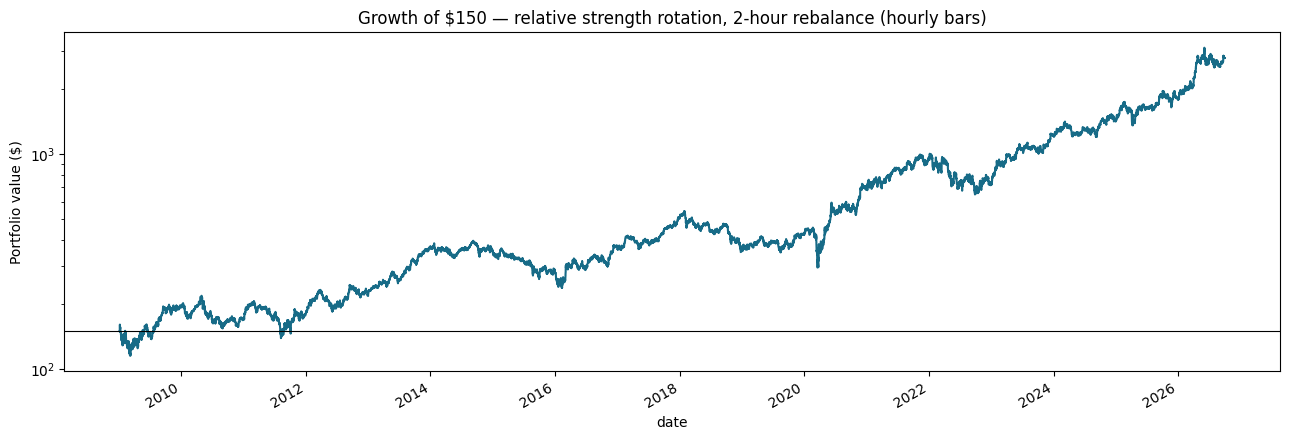

In [7]:
fig, ax = plt.subplots(figsize=(13, 4.5))
(150 * wealth / wealth.iloc[0]).plot(ax=ax, color='#176b87',
    title='Growth of $150 — relative strength rotation, 2-hour rebalance (hourly bars)')
ax.set_ylabel('Portfolio value ($)')
ax.set_yscale('log')
ax.axhline(150, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()


## Monthly performance

The 2-hourly return series resampled to month-end, so this strategy can be read on the same
monthly heatmap as every other notebook even though it actually trades every 2 hours.

In [8]:
monthly_wealth = wealth.resample('ME').last()
today_ts = pd.Timestamp.now(tz='UTC')
if len(monthly_wealth) and (monthly_wealth.index[-1].year, monthly_wealth.index[-1].month) == (today_ts.year, today_ts.month):
    monthly_wealth = monthly_wealth.iloc[:-1]
monthly_returns = monthly_wealth.pct_change().dropna()

table = (monthly_returns * 100).rename('ret').to_frame()
table['year'] = table.index.year
table['month'] = table.index.strftime('%b')
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_table = table.pivot(index='year', columns='month', values='ret').reindex(columns=month_order)

annual_return = monthly_returns.groupby(monthly_returns.index.year).apply(lambda x: (1 + x).prod() - 1) * 100
monthly_table['Year'] = annual_return

monthly_summary = pd.Series({
    'months': len(monthly_returns),
    'positive_months': int((monthly_returns > 0).sum()),
    'pct_positive_months': float((monthly_returns > 0).mean()),
    'avg_monthly_return': float(monthly_returns.mean()),
    'median_monthly_return': float(monthly_returns.median()),
    'best_month': monthly_returns.idxmax().strftime('%Y-%m'),
    'best_month_return': float(monthly_returns.max()),
    'worst_month': monthly_returns.idxmin().strftime('%Y-%m'),
    'worst_month_return': float(monthly_returns.min()),
})

styled = (
    monthly_table.round(1)
    .style.format(precision=1, na_rep='')
    .background_gradient(cmap='RdYlGn', axis=None, vmin=-20, vmax=20, subset=month_order)
    .set_caption('Monthly return (%) by year')
)
display(styled)
display(monthly_summary.to_frame('value'))


month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Year
year,,,,,,,,,,,,,
2009,,-6.4,2.4,9.7,6.6,-3.3,6.2,11.5,10.0,-4.3,3.4,3.1,44.0
2010,-9.0,-0.2,10.7,10.1,-15.8,-6.6,1.1,-9.4,8.2,2.7,-8.6,8.6,-12.0
2011,14.1,4.9,-4.4,-1.2,-1.1,-7.2,-7.2,-1.6,-3.4,17.8,-1.2,-0.7,5.9
2012,9.4,10.4,4.4,-6.1,-9.8,4.5,-1.0,6.6,10.8,-4.3,1.0,-2.5,22.9
2013,8.1,0.6,7.8,-1.8,8.4,-6.7,9.0,2.9,8.2,7.5,7.0,3.0,67.2
2014,-5.9,1.6,1.4,-4.4,-2.1,5.9,0.5,7.9,-1.7,-5.5,1.6,-4.2,-5.9
2015,-6.2,7.8,-4.5,-2.4,-0.5,-2.8,-0.8,-6.8,-8.1,8.3,-2.1,-1.2,-18.8
2016,-10.1,1.2,16.8,5.1,-5.1,0.6,8.7,-0.3,3.1,-9.6,14.3,3.3,27.3
2017,1.6,12.1,-0.1,-7.3,0.7,1.0,0.8,4.4,8.7,3.2,6.5,2.6,38.3


,value
months,212
positive_months,121
pct_positive_months,0.570755
avg_monthly_return,0.016876
median_monthly_return,0.013845
best_month,2020-11
best_month_return,0.309071
worst_month,2010-05
worst_month_return,-0.158296


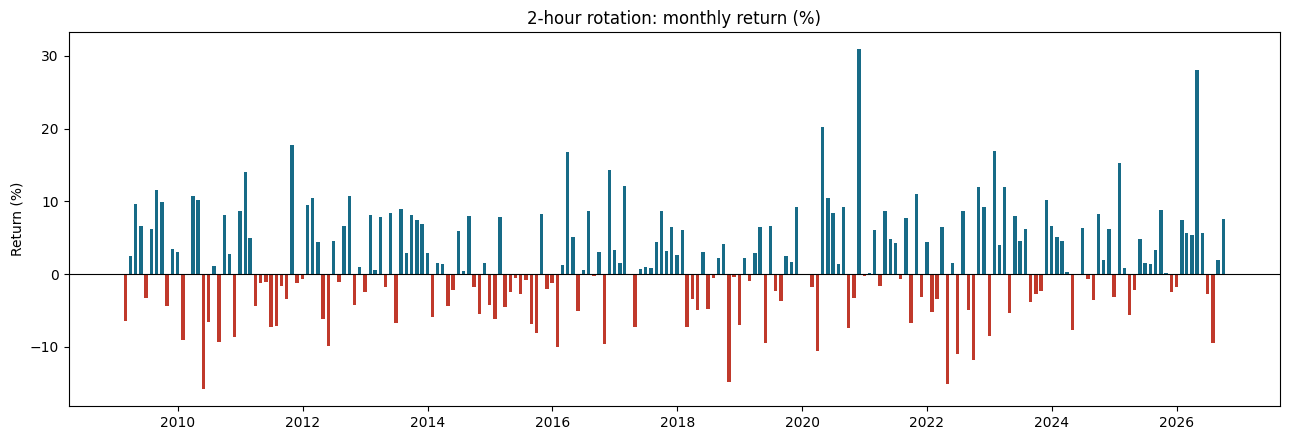

In [9]:
colors = np.where(monthly_returns >= 0, '#176b87', '#c0392b')
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(monthly_returns.index, monthly_returns.values * 100, width=20, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('2-hour rotation: monthly return (%)')
ax.set_ylabel('Return (%)')
plt.tight_layout()
plt.show()


## Caveats and next improvements

- **This strategy has never been backtested before now.** The live script
  (`relative_strength_rotation_webull_intraday.py`) went live with `DRY_RUN=True` as its only
  safeguard, not a validated history. Everything above is the first look at what this specific
  signal/cadence combination would have done historically — treat it accordingly.
- **No transaction costs, at ~879 rebalance cycles a year.** Every notebook in this project
  skips commissions and spread, but the monthly strategies only turn over ~12 times a year;
  this one turns over roughly 70x more often. Real trading costs that are a rounding error for
  the monthly strategy would very plausibly dominate this one's real-world return. This is the
  single most important number this notebook is missing.
- **The live system is throttled by settled cash; this backtest is not.** The live script only
  ever buys with settled cash (deliberately, to make good-faith violations structurally
  impossible — see that script's docstring), which means in practice it will often have less
  to deploy each cycle than a full rebalance would want. This backtest assumes unconstrained
  full rebalancing every cycle, so real performance should be expected to lag what's shown
  here, not match it.
- **Hourly closes, not real intraday execution.** Entries and exits are assumed to fill at
  exactly the bar close with no slippage, spread, or gap risk — the same simplifying
  assumption the daily event-driven notebooks (breakout, RSI pullback, Z-score) make, except
  this rebalances roughly 7x more often per trading day than those strategies' signals can
  even fire.
- **Look-ahead / survivorship bias in the universe**: `equities-list.csv` is today's list of
  halal candidates, projected backward — same caveat as every other notebook in this project.
- **Isolated missing hourly bars are forward-filled** (up to one full session) to keep the
  rolling 6-bar lookback contiguous; a ticker with a longer real gap is simply unscoreable at
  that gap\'s decision points, not corrected for.
- A serious version of this strategy would need realistic per-trade cost assumptions before
  its backtest numbers mean anything close to what the monthly strategies\' numbers mean, and
  should probably model the live system\'s settled-cash throttling explicitly rather than
  assume it away.
